## LaDe 19: Regional Pickup Workload Distribution (Flag 19)

### Dataset Overview

Constructed LaDe-style Shanghai pickup data: 823 tasks, 32 courier-days, 61215 GPS points. All times are local Shanghai time. Task destinations and GPS paths lie on the archived OSM street network; oneway directions are respected, while turn-restriction relations are not modeled. Moving GPS steps preserve all road vertices and have maximum spacing 45 m. speed_kmh and activity_state describe the immediately preceding segment. AOIs are explicitly constructed circular catchments within one constructed region, not original LaDe AOI polygons. Task events, service windows, couriers and assignments are constructed. accept_gps_time is the closest recorded GPS time to task acceptance; acceptance_distance_km uses interpolated position at the exact event time. Pickup GPS is recorded at the actual service-completion position. The last pickup is the observed end of each courier-day. Stationary waiting is retained in the GPS trace, but excluded from active_duration_hours, which sums travelling and servicing time.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Identify how pickup workload is distributed among couriers in the selected region.

Role: Last-mile logistics analyst


Category: regional_pickup_workload_distribution


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "pickup_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How much can travel and active duration differ at comparable task counts?

#### Analysis action

Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.

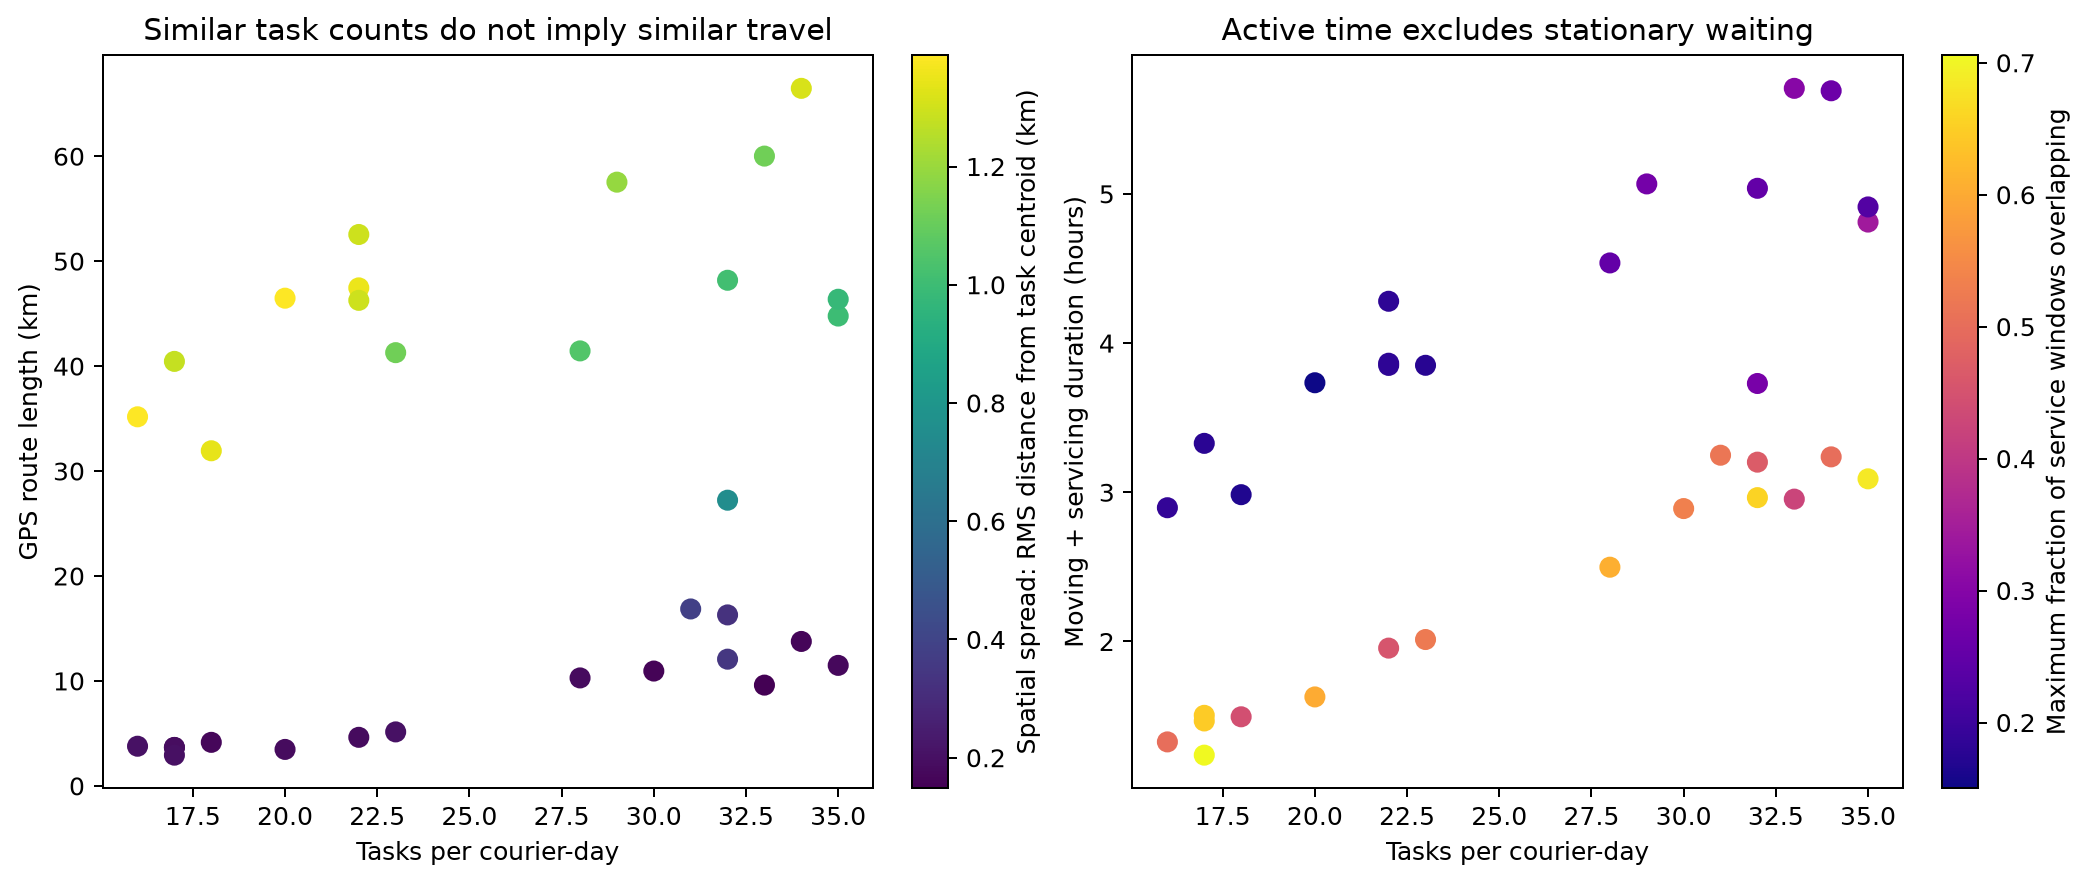

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

supplement = pd.read_csv("courier_days.csv")
aois = pd.read_csv("aois.csv")


def workload_effort(df, user_df, supplement, aois):
    d = supplement.copy()
    small = d[d.task_count <= 24].copy()
    small["coverage"] = np.where(
        small.aoi_count >= 5, "Broad (5+ AOIs)", "Compact (2–3 AOIs)"
    )
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
    p = axes[0].scatter(
        d.task_count, d.route_length_km, c=d.spatial_spread_km, cmap="viridis", s=55
    )
    fig.colorbar(
        p, ax=axes[0], label="Spatial spread: RMS distance from task centroid (km)"
    )
    axes[0].set(
        xlabel="Tasks per courier-day",
        ylabel="GPS route length (km)",
        title="Similar task counts do not imply similar travel",
    )
    p = axes[1].scatter(
        d.task_count,
        d.active_duration_hours,
        c=d.window_overlap_concentration,
        cmap="plasma",
        s=55,
    )
    fig.colorbar(p, ax=axes[1], label="Maximum fraction of service windows overlapping")
    axes[1].set(
        xlabel="Tasks per courier-day",
        ylabel="Moving + servicing duration (hours)",
        title="Active time excludes stationary waiting",
    )
    pairs = []
    for _, day in small.groupby("service_date"):
        for a in day[day.aoi_count <= 3].itertuples():
            for b in day[day.aoi_count >= 5].itertuples():
                if abs(a.task_count - b.task_count) <= 3:
                    pairs.append(
                        {
                            "compact": a.trajectory_id,
                            "broad": b.trajectory_id,
                            "task_count_difference": abs(a.task_count - b.task_count),
                            "route_ratio": b.route_length_km / a.route_length_km,
                            "active_duration_ratio": (
                                b.active_duration_hours / a.active_duration_hours
                            ),
                        }
                    )
    means = small.groupby("coverage")[
        [
            "task_count",
            "route_length_km",
            "active_duration_hours",
            "spatial_spread_km",
            "window_overlap_concentration",
        ]
    ].mean()
    return {
        "matched_same_day_pairs_within_3_tasks": len(pairs),
        "matched_pair_median_route_ratio": float(
            np.median([x["route_ratio"] for x in pairs])
        ),
        "matched_pair_median_active_duration_ratio": float(
            np.median([x["active_duration_ratio"] for x in pairs])
        ),
        "low_volume_courier_day_group_means": means.to_dict(),
        "matched_pairs": pairs,
    }


evidence = workload_effort(df, user_df, supplement, aois)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (10 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "workload_effort",
  "insight_type": "overall_pattern",
  "insight": "Couriers handling similar numbers of tasks can have very different route lengths and active durations when their pickups differ in spatial spread and time-window concentration.",
  "insight_value": {
    "matched_same_day_pairs_within_3_tasks": 8,
    "matched_pair_median_route_ratio": 11.544971943089806,
    "matched_pair_median_active_duration_ratio": 2.3518764943649493,
    "low_volume_courier_day_group_means": {
      "task_count": {
        "Broad (5+ AOIs)": 20.0,
        "Compact (2–3 AOIs)": 18.75
      },
      "route_length_km": {
        "Broad (5+ AOIs)": 42.69619352075867,
        "Compact (2–3 AOIs)": 3.9269671300180393
      },
      "active_duration_hours": {
        "Broad (5+ AOIs)": 3.5986098137518403,
        "Compact (2–3 AOIs)": 1.5787764129280557
      },
      "spatial_spread_km": {
        "Broad (5+ AOIs)": 1.307605426723997,
        "Compact (2–3 AOIs)": 0.187461339022127
      },
      "window_overlap_concentration": {
        "Broad (5+ AOIs)": 0.17500060547934587,
        "Compact (2–3 AOIs)": 0.5650911286780852
      }
    },
    "matched_pairs": [
      {
        "compact": "L19_courier_A_20260817",
        "broad": "L19_courier_C_20260817",
        "task_count_difference": 2,
        "route_ratio": 11.204358397971141,
        "active_duration_ratio": 2.4971932737610483
      },
      {
        "compact": "L19_courier_B_20260817",
        "broad": "L19_courier_C_20260817",
        "task_count_difference": 3,
        "route_ratio": 12.685443439036685,
        "active_duration_ratio": 2.480940491383538
      },
      {
        "compact": "L19_courier_B_20260819",
        "broad": "L19_courier_C_20260819",
        "task_count_difference": 3,
        "route_ratio": 11.885585488208472,
        "active_duration_ratio": 2.3649303105821664
      },
      {
        "compact": "L19_courier_B_20260819",
        "broad": "L19_courier_D_20260819",
        "task_count_difference": 2,
        "route_ratio": 13.662726979468749,
        "active_duration_ratio": 2.364457682728279
      },
      {
        "compact": "L19_courier_A_20260824",
        "broad": "L19_courier_C_20260824",
        "task_count_difference": 1,
        "route_ratio": 9.614525883994249,
        "active_duration_ratio": 2.3392953060016195
      },
      {
        "compact": "L19_courier_B_20260824",
        "broad": "L19_courier_D_20260824",
        "task_count_difference": 0,
        "route_ratio": 10.001406474930896,
        "active_duration_ratio": 1.976334868274258
      },
      {
        "compact": "L19_courier_A_20260826",
        "broad": "L19_courier_C_20260826",
        "task_count_difference": 1,
        "route_ratio": 10.909444926793533,
        "active_duration_ratio": 2.0334994507811017
      },
      {
        "compact": "L19_courier_A_20260826",
        "broad": "L19_courier_D_20260826",
        "task_count_difference": 0,
        "route_ratio": 13.819165750422735,
        "active_duration_ratio": 2.26789337526484
      }
    ]
  },
  "question": "How much can travel and active duration differ at comparable task counts?",
  "actionable_insight": "Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "How much can travel and active duration differ at comparable task counts?",
    "file": "visualizations/insight_1.png",
    "description": "Both panels and all statistics are calculated from the emitted CSV tables."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nsupplement=pd.read_csv(\"courier_days.csv\")\naois=pd.read_csv(\"aois.csv\")\n\ndef workload_effort(df,user_df,supplement,aois):\n    d=supplement.copy();small=d[d.task_count<=24].copy()\n    small['coverage']=np.where(small.aoi_count>=5,'Broad (5+ AOIs)','Compact (2–3 AOIs)')\n    fig,axes=plt.subplots(1,2,figsize=(11.5,4.8),constrained_layout=True)\n    p=axes[0].scatter(d.task_count,d.route_length_km,c=d.spatial_spread_km,cmap='viridis',s=55)\n    fig.colorbar(p,ax=axes[0],label='Spatial spread: RMS distance from task centroid (km)')\n    axes[0].set(xlabel='Tasks per courier-day',ylabel='GPS route length (km)',title='Similar task counts do not imply similar travel')\n    p=axes[1].scatter(d.task_count,d.active_duration_hours,c=d.window_overlap_concentration,cmap='plasma',s=55)\n    fig.colorbar(p,ax=axes[1],label='Maximum fraction of service windows overlapping')\n    axes[1].set(xlabel='Tasks per courier-day',ylabel='Moving + servicing duration (hours)',title='Active time excludes stationary waiting')\n    pairs=[]\n    for _,day in small.groupby('service_date'):\n        for a in day[day.aoi_count<=3].itertuples():\n            for b in day[day.aoi_count>=5].itertuples():\n                if abs(a.task_count-b.task_count)<=3:\n                    pairs.append({'compact':a.trajectory_id,'broad':b.trajectory_id,'task_count_difference':abs(a.task_count-b.task_count),\n                        'route_ratio':b.route_length_km/a.route_length_km,'active_duration_ratio':b.active_duration_hours/a.active_duration_hours})\n    means=small.groupby('coverage')[['task_count','route_length_km','active_duration_hours','spatial_spread_km','window_overlap_concentration']].mean()\n    return {'matched_same_day_pairs_within_3_tasks':len(pairs),'matched_pair_median_route_ratio':float(np.median([x['route_ratio'] for x in pairs])),\n            'matched_pair_median_active_duration_ratio':float(np.median([x['active_duration_ratio'] for x in pairs])),\n            'low_volume_courier_day_group_means':means.to_dict(),'matched_pairs':pairs}\n\nevidence=workload_effort(df,user_df,supplement,aois)\nprint(evidence)\nplt.show()",
  "difficulty_level": 10,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "accept_time",
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_position",
    "gps_time",
    "gps_position",
    "task_id",
    "aoi_id"
  ]
}

### **Question 2**: Do high-volume days change staffing at busy AOIs and the stability of courier assignments?

#### Analysis action

Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.

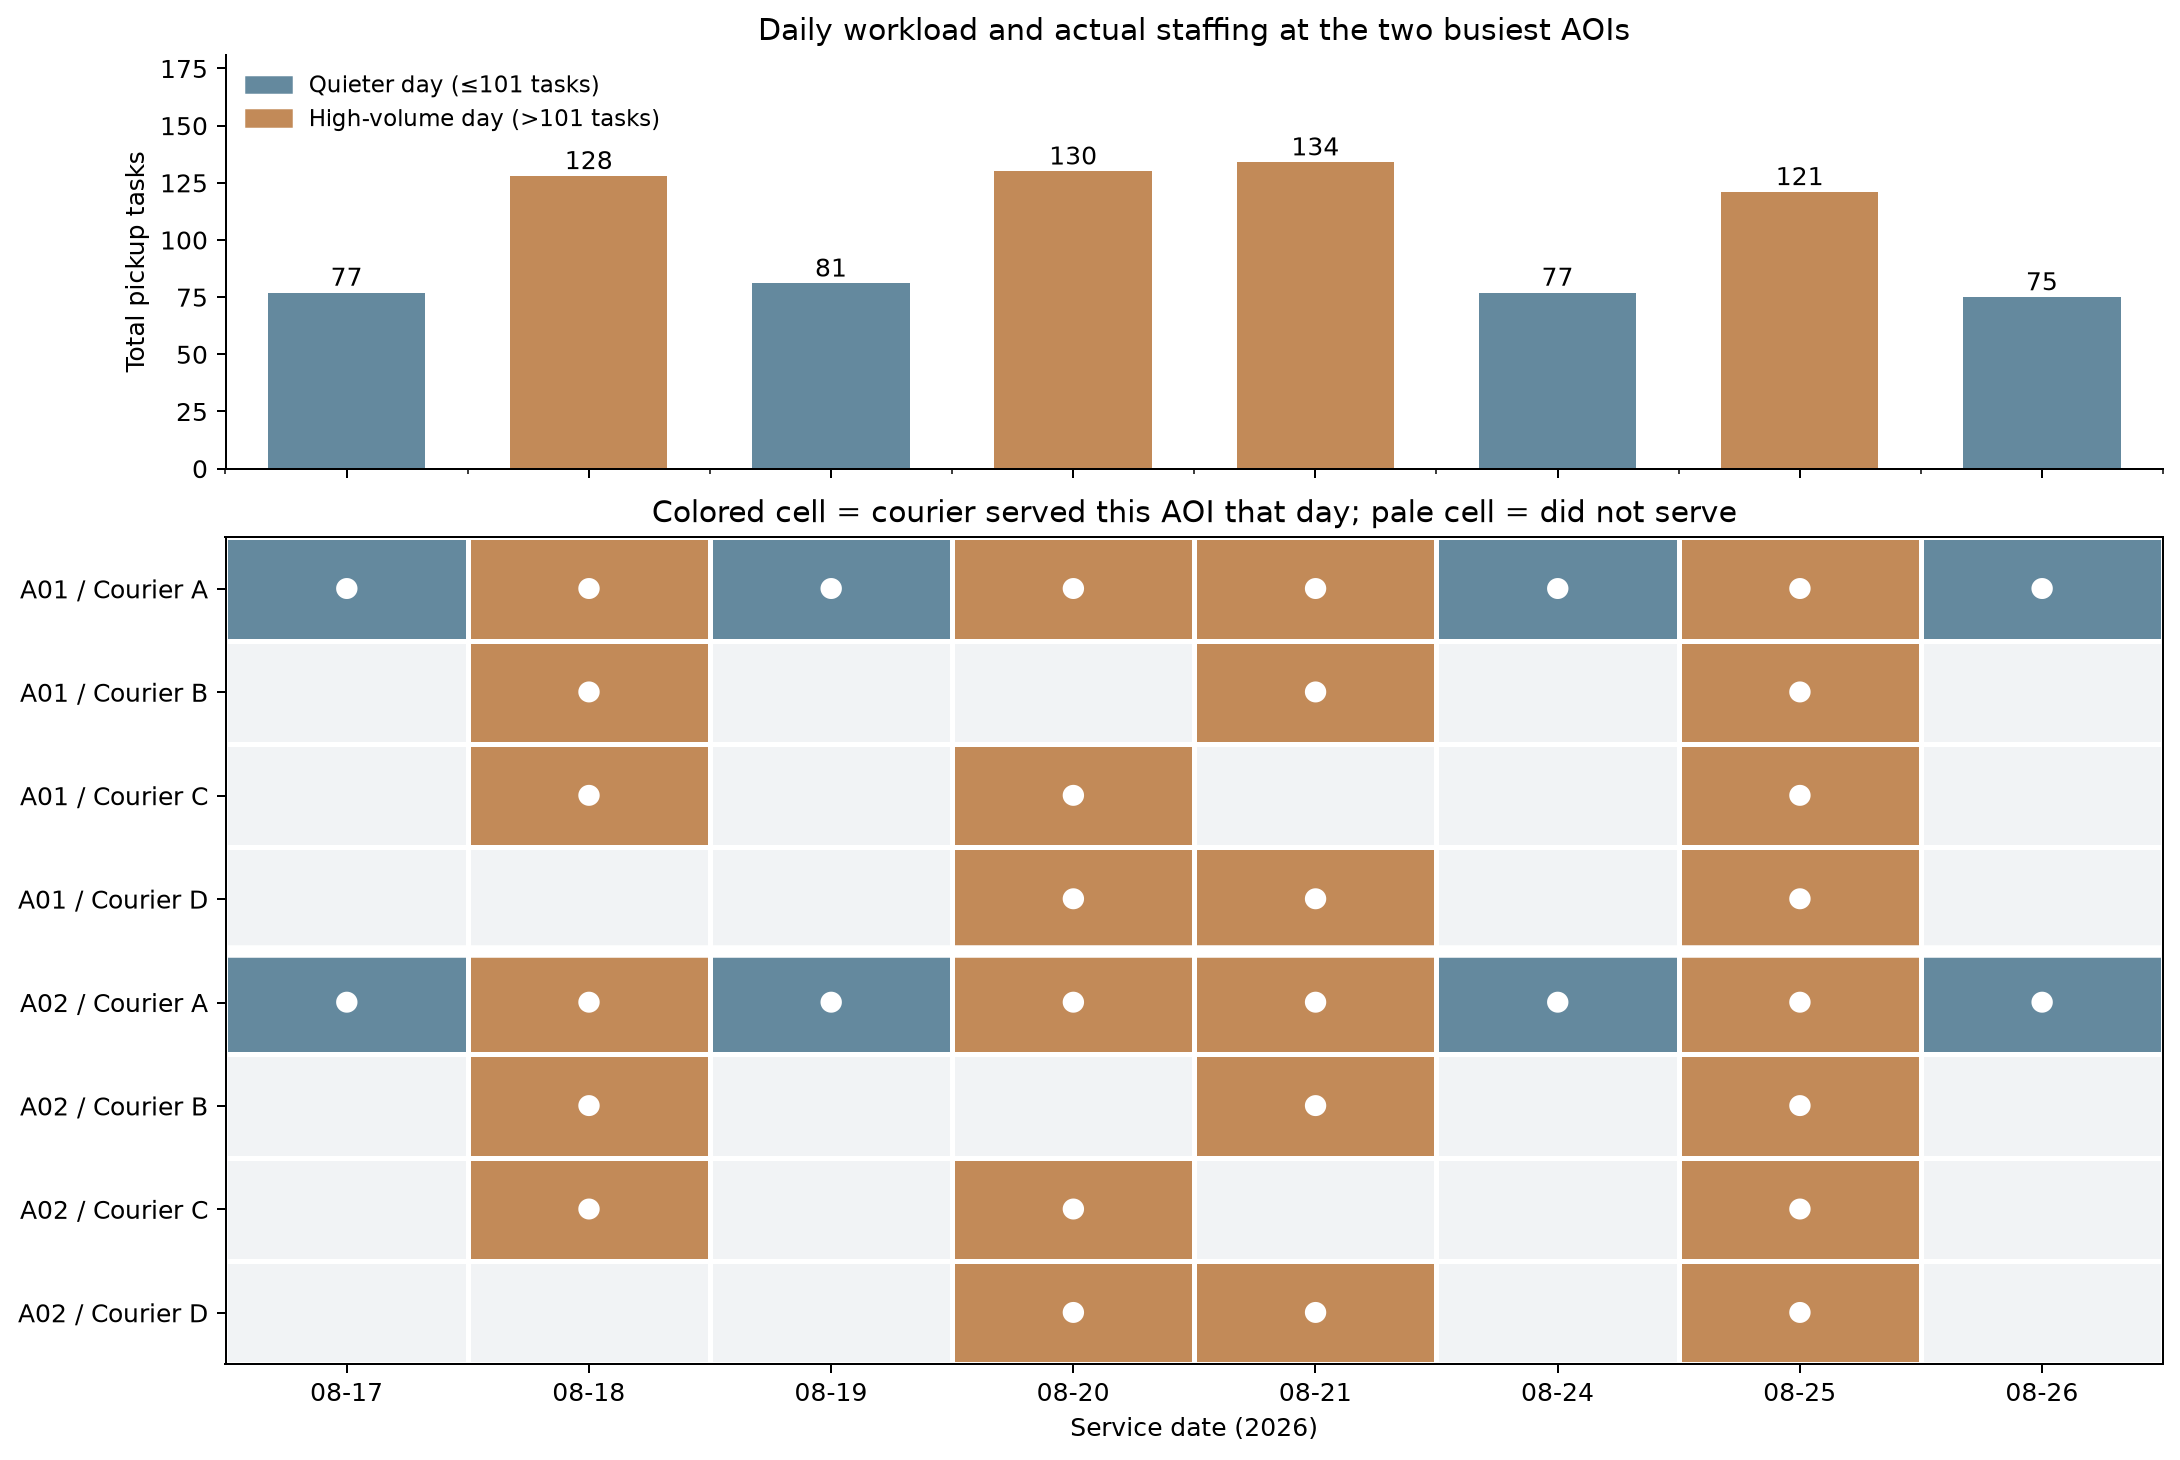

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

supplement = pd.read_csv("courier_days.csv")
aois = pd.read_csv("aois.csv")


def busy_aoi_staffing(df, user_df, supplement, aois):
    daily = df.groupby("service_date").size()
    cut = float(daily.median())
    high = daily[daily > cut].index
    table = (
        df.groupby(["service_date", "aoi_id"])
        .agg(tasks=("pickup_task_id", "size"), couriers=("courier_id", "nunique"))
        .reset_index()
    )
    table["volume_day"] = np.where(
        table.service_date.isin(high), "High-volume", "Quieter"
    )
    busiest = df.groupby("aoi_id").size().nlargest(2).index.tolist()
    q = table[table.aoi_id.isin(busiest)]
    means = (
        q.groupby(["aoi_id", "volume_day"])
        .couriers.mean()
        .unstack()
        .reindex(columns=["Quieter", "High-volume"])
    )
    stability = {}
    busy_stability = {}
    for regime, dates in [
        ("Quieter", daily[daily <= cut].index),
        ("High-volume", high),
    ]:
        values = []
        busy_values = []
        for aoi in sorted(df.aoi_id.unique()):
            sets = [
                set(df.loc[df.service_date.eq(date) & df.aoi_id.eq(aoi), "courier_id"])
                for date in sorted(dates)
            ]
            scores = [len(a & b) / len(a | b) for a, b in zip(sets, sets[1:]) if a | b]
            values.extend(scores)
            if aoi in busiest:
                busy_values.extend(scores)
        stability[regime] = float(np.mean(values))
        busy_stability[regime] = float(np.mean(busy_values))
    from matplotlib.colors import ListedColormap
    from matplotlib.patches import Patch

    dates = sorted(daily.index)
    couriers = sorted(df.courier_id.unique())
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12, 8),
        sharex=True,
        constrained_layout=True,
        gridspec_kw={"height_ratios": [1, 2]},
    )
    colors = ["#c28a58" if date in high else "#64899e" for date in dates]
    axes[0].bar(np.arange(len(dates)), daily.reindex(dates), color=colors, width=0.65)
    for i, date in enumerate(dates):
        axes[0].text(i, daily[date] + 3, str(daily[date]), ha="center")
    axes[0].set(
        ylabel="Total pickup tasks",
        ylim=(0, float(daily.max()) * 1.35),
        title="Daily workload and actual staffing at the two busiest AOIs",
    )
    axes[0].legend(
        handles=[
            Patch(color="#64899e", label=f"Quieter day (≤{cut:g} tasks)"),
            Patch(color="#c28a58", label=f"High-volume day (>{cut:g} tasks)"),
        ],
        loc="upper left",
        fontsize=9,
        frameon=False,
    )
    rows = [(aoi, courier) for aoi in busiest for courier in couriers]
    cells = np.zeros((len(rows), len(dates)))
    for i, (aoi, courier) in enumerate(rows):
        for j, date in enumerate(dates):
            served = (
                (df.aoi_id == aoi)
                & (df.courier_id == courier)
                & (df.service_date == date)
            ).any()
            if served:
                cells[i, j] = 2 if date in high else 1
    axes[1].imshow(
        cells,
        cmap=ListedColormap(["#f1f3f5", "#64899e", "#c28a58"]),
        vmin=0,
        vmax=2,
        aspect="auto",
        interpolation="nearest",
    )
    for i, j in zip(*np.nonzero(cells)):
        axes[1].text(j, i, "●", ha="center", va="center", color="white", fontsize=11)
    axes[1].set(
        xticks=np.arange(len(dates)),
        xticklabels=[date[5:] for date in dates],
        yticks=np.arange(len(rows)),
        yticklabels=[f'{aoi} / Courier {c.split("_")[-1]}' for aoi, c in rows],
        xlabel="Service date (2026)",
        title=(
            "Colored cell = courier served this AOI that day; pale cell = did not serve"
        ),
    )
    axes[1].set_xticks(np.arange(-0.5, len(dates), 1), minor=True)
    axes[1].set_yticks(np.arange(-0.5, len(rows), 1), minor=True)
    axes[1].grid(which="minor", color="white", linewidth=2)
    axes[1].tick_params(which="minor", bottom=False, left=False)
    axes[1].axhline(len(couriers) - 0.5, color="white", linewidth=5)
    axes[0].spines[["top", "right"]].set_visible(False)
    return {
        "daily_task_counts": daily.to_dict(),
        "high_volume_threshold_tasks": cut,
        "busiest_aois": busiest,
        "mean_couriers_at_busiest_aois": means.to_dict(),
        "courier_aoi_assignment_stability": stability,
        "busy_aoi_assignment_stability": busy_stability,
    }


evidence = busy_aoi_staffing(df, user_df, supplement, aois)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "busy_aoi_staffing",
  "insight_type": "factor_relationship",
  "insight": "On high-volume days, the busiest AOIs are served by more couriers, while quieter days show more stable courier–AOI service patterns.",
  "insight_value": {
    "daily_task_counts": {
      "2026-08-17": 77,
      "2026-08-18": 128,
      "2026-08-19": 81,
      "2026-08-20": 130,
      "2026-08-21": 134,
      "2026-08-24": 77,
      "2026-08-25": 121,
      "2026-08-26": 75
    },
    "high_volume_threshold_tasks": 101.0,
    "busiest_aois": [
      "A01",
      "A02"
    ],
    "mean_couriers_at_busiest_aois": {
      "Quieter": {
        "A01": 1.0,
        "A02": 1.0
      },
      "High-volume": {
        "A01": 3.25,
        "A02": 3.25
      }
    },
    "courier_aoi_assignment_stability": {
      "Quieter": 1.0,
      "High-volume": 0.9074074074074074
    },
    "busy_aoi_assignment_stability": {
      "Quieter": 1.0,
      "High-volume": 0.5833333333333334
    }
  },
  "question": "Do high-volume days change staffing at busy AOIs and the stability of courier assignments?",
  "actionable_insight": "Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Do high-volume days change staffing at busy AOIs and the stability of courier assignments?",
    "file": "visualizations/insight_2.png",
    "description": "Both panels and all statistics are calculated from the emitted CSV tables."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nsupplement=pd.read_csv(\"courier_days.csv\")\naois=pd.read_csv(\"aois.csv\")\n\ndef busy_aoi_staffing(df,user_df,supplement,aois):\n    daily=df.groupby('service_date').size();cut=float(daily.median());high=daily[daily>cut].index\n    table=df.groupby(['service_date','aoi_id']).agg(tasks=('pickup_task_id','size'),couriers=('courier_id','nunique')).reset_index()\n    table['volume_day']=np.where(table.service_date.isin(high),'High-volume','Quieter')\n    busiest=df.groupby('aoi_id').size().nlargest(2).index.tolist();q=table[table.aoi_id.isin(busiest)]\n    means=q.groupby(['aoi_id','volume_day']).couriers.mean().unstack().reindex(columns=['Quieter','High-volume'])\n    stability={};busy_stability={}\n    for regime,dates in [('Quieter',daily[daily<=cut].index),('High-volume',high)]:\n        values=[];busy_values=[]\n        for aoi in sorted(df.aoi_id.unique()):\n            sets=[set(df.loc[df.service_date.eq(date)&df.aoi_id.eq(aoi),'courier_id']) for date in sorted(dates)]\n            scores=[len(a&b)/len(a|b) for a,b in zip(sets,sets[1:]) if a|b]\n            values.extend(scores)\n            if aoi in busiest:busy_values.extend(scores)\n        stability[regime]=float(np.mean(values))\n        busy_stability[regime]=float(np.mean(busy_values))\n    from matplotlib.colors import ListedColormap\n    from matplotlib.patches import Patch\n    dates=sorted(daily.index);couriers=sorted(df.courier_id.unique())\n    fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True,\n        gridspec_kw={'height_ratios':[1,2]})\n    colors=['#c28a58' if date in high else '#64899e' for date in dates]\n    axes[0].bar(np.arange(len(dates)),daily.reindex(dates),color=colors,width=.65)\n    for i,date in enumerate(dates):axes[0].text(i,daily[date]+3,str(daily[date]),ha='center')\n    axes[0].set(ylabel='Total pickup tasks',ylim=(0,float(daily.max())*1.35),\n        title='Daily workload and actual staffing at the two busiest AOIs')\n    axes[0].legend(handles=[Patch(color='#64899e',label=f'Quieter day (≤{cut:g} tasks)'),\n        Patch(color='#c28a58',label=f'High-volume day (>{cut:g} tasks)')],loc='upper left',fontsize=9,frameon=False)\n    rows=[(aoi,courier) for aoi in busiest for courier in couriers]\n    cells=np.zeros((len(rows),len(dates)))\n    for i,(aoi,courier) in enumerate(rows):\n        for j,date in enumerate(dates):\n            served=((df.aoi_id==aoi)&(df.courier_id==courier)&(df.service_date==date)).any()\n            if served:cells[i,j]=2 if date in high else 1\n    axes[1].imshow(cells,cmap=ListedColormap(['#f1f3f5','#64899e','#c28a58']),\n        vmin=0,vmax=2,aspect='auto',interpolation='nearest')\n    for i,j in zip(*np.nonzero(cells)):\n        axes[1].text(j,i,'●',ha='center',va='center',color='white',fontsize=11)\n    axes[1].set(xticks=np.arange(len(dates)),xticklabels=[date[5:] for date in dates],\n        yticks=np.arange(len(rows)),yticklabels=[f'{aoi} / Courier {c.split(\"_\")[-1]}' for aoi,c in rows],\n        xlabel='Service date (2026)',title='Colored cell = courier served this AOI that day; pale cell = did not serve')\n    axes[1].set_xticks(np.arange(-.5,len(dates),1),minor=True)\n    axes[1].set_yticks(np.arange(-.5,len(rows),1),minor=True)\n    axes[1].grid(which='minor',color='white',linewidth=2)\n    axes[1].tick_params(which='minor',bottom=False,left=False)\n    axes[1].axhline(len(couriers)-.5,color='white',linewidth=5)\n    axes[0].spines[['top','right']].set_visible(False)\n    return {'daily_task_counts':daily.to_dict(),'high_volume_threshold_tasks':cut,'busiest_aois':busiest,\n            'mean_couriers_at_busiest_aois':means.to_dict(),'courier_aoi_assignment_stability':stability,'busy_aoi_assignment_stability':busy_stability}\n\nevidence=busy_aoi_staffing(df,user_df,supplement,aois)\nprint(evidence)\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "aoi_id",
    "pickup_time",
    "task_id"
  ]
}

### **Question 3**: Are later-accepted tasks picked up later and often near the end of their service windows?

#### Analysis action

Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.

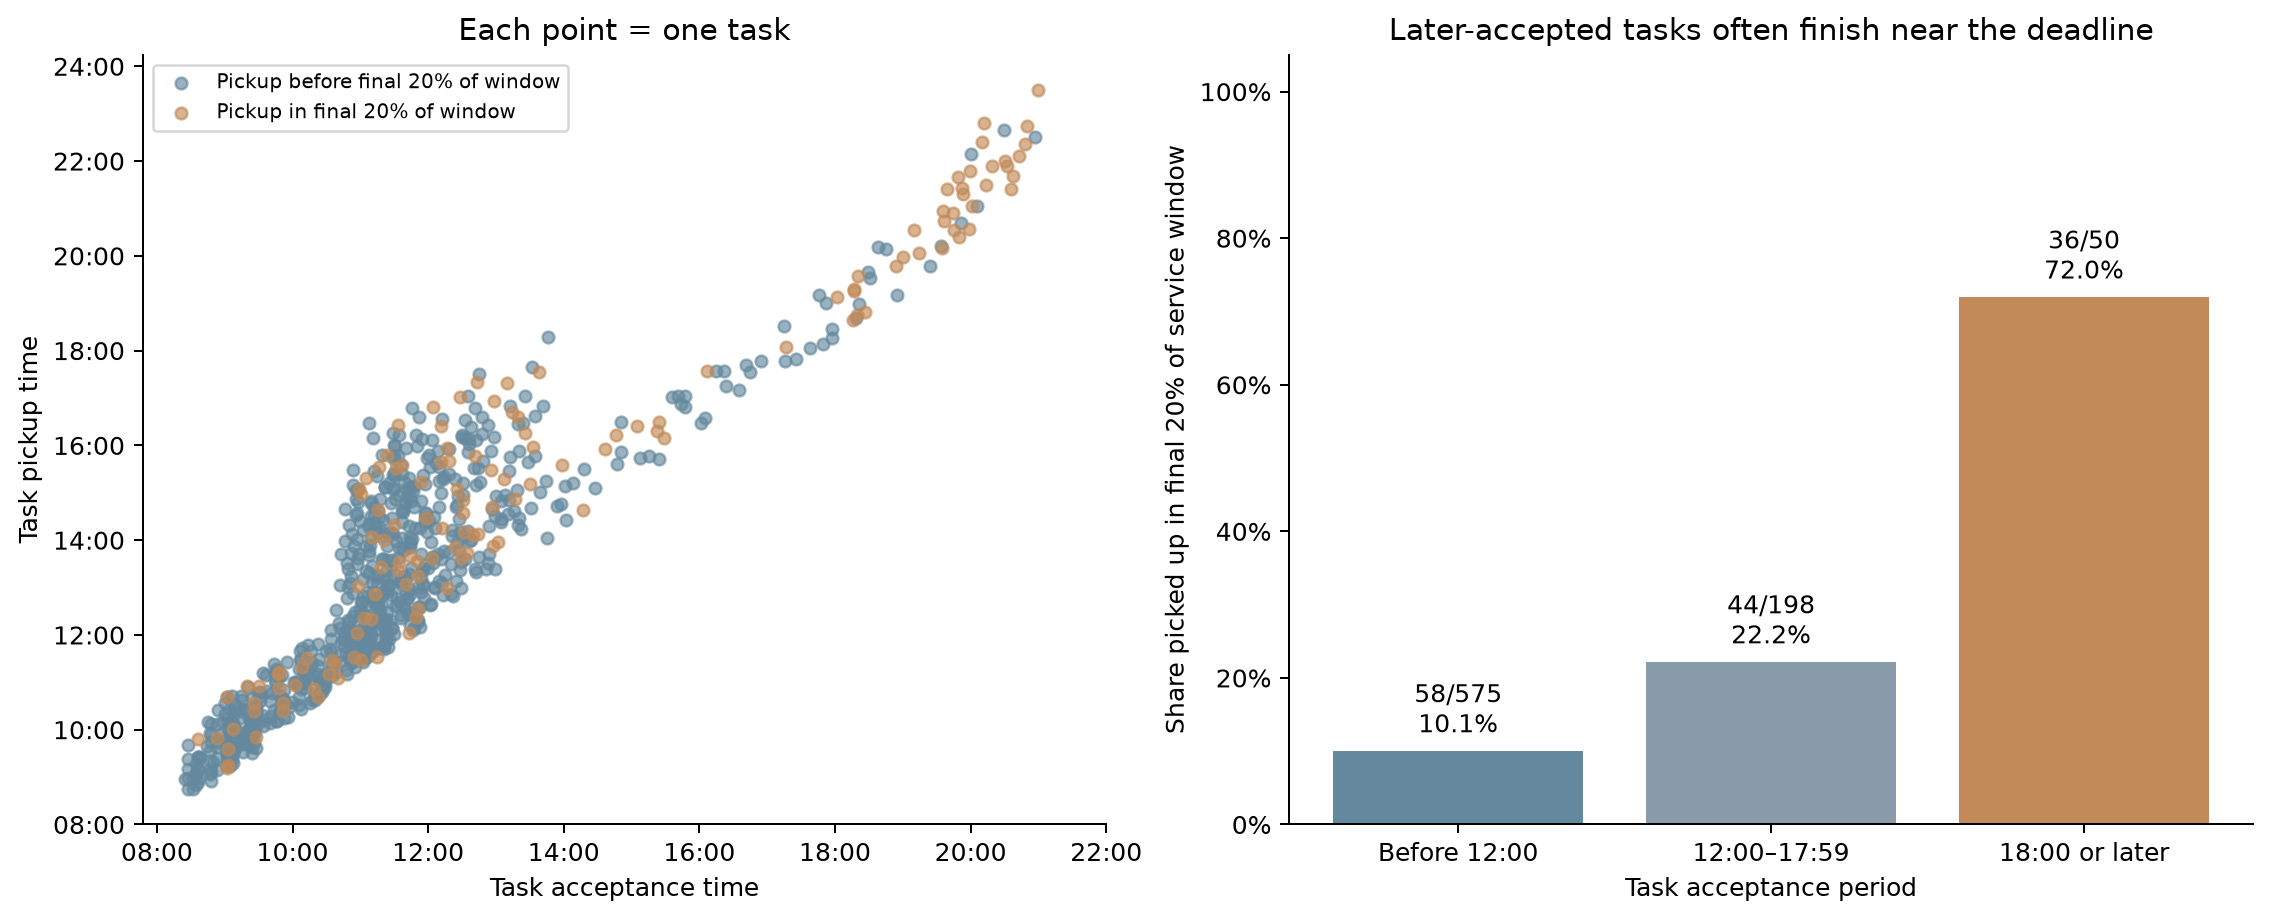

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

supplement = pd.read_csv("courier_days.csv")
aois = pd.read_csv("aois.csv")


def late_finishing(df, user_df, supplement, aois):
    d = df.copy()
    for col in ["accept_time", "pickup_time", "time_window_start", "time_window_end"]:
        d[col] = pd.to_datetime(d[col], format="mixed")
    d["accept_hour"] = (
        d.accept_time - d.accept_time.dt.normalize()
    ).dt.total_seconds() / 3600
    d["pickup_hour"] = (
        d.pickup_time - d.pickup_time.dt.normalize()
    ).dt.total_seconds() / 3600
    d["window_position"] = (d.pickup_time - d.time_window_start) / (
        d.time_window_end - d.time_window_start
    )
    d["near_end"] = d.window_position.between(0.8, 1)
    names = ["Before 12:00", "12:00–17:59", "18:00 or later"]
    d["acceptance_period"] = pd.cut(
        d.accept_hour, [0, 12, 18, 24], right=False, labels=names
    )
    stats = d.groupby("acceptance_period", observed=True).agg(
        tasks=("pickup_task_id", "size"),
        near_end_count=("near_end", "sum"),
        near_end_share=("near_end", "mean"),
        median_pickup_hour=("pickup_hour", "median"),
    )
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), constrained_layout=True)
    for near, color, label in [
        (False, "#64899e", "Pickup before final 20% of window"),
        (True, "#c28a58", "Pickup in final 20% of window"),
    ]:
        q = d[d.near_end == near]
        axes[0].scatter(
            q.accept_hour, q.pickup_hour, color=color, s=22, alpha=0.65, label=label
        )
    axes[0].set(
        xlabel="Task acceptance time",
        ylabel="Task pickup time",
        title="Each point = one task",
        xticks=range(8, 23, 2),
        yticks=range(8, 25, 2),
    )
    for axis in [axes[0].xaxis, axes[0].yaxis]:
        axis.set_major_formatter(lambda v, _: f"{int(v):02}:00")
    axes[0].legend(fontsize=8, loc="upper left")
    axes[1].bar(names, stats.near_end_share, color=["#64899e", "#899cab", "#c28a58"])
    for i, row in enumerate(stats.itertuples()):
        axes[1].text(
            i,
            row.near_end_share + 0.025,
            f"{row.near_end_count}/{row.tasks}\n{row.near_end_share:.1%}",
            ha="center",
        )
    axes[1].set(
        ylabel="Share picked up in final 20% of service window",
        ylim=(0, 1.05),
        xlabel="Task acceptance period",
        title="Later-accepted tasks often finish near the deadline",
    )
    axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
    late = d[d.accept_hour >= 18]
    return {
        "tasks": len(d),
        "late_acceptance_threshold_hour": 18,
        "near_window_end_threshold": 0.8,
        "acceptance_pickup_spearman": float(
            d.accept_hour.corr(d.pickup_hour, method="spearman")
        ),
        "acceptance_period_statistics": stats.to_dict(),
        "late_task_count": len(late),
        "late_near_window_end_count": int(late.near_end.sum()),
        "late_near_window_end_share": float(late.near_end.mean()),
        "late_median_minutes_until_window_end": float(
            (late.time_window_end - late.pickup_time).dt.total_seconds().median() / 60
        ),
    }


evidence = late_finishing(df, user_df, supplement, aois)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "late_finishing",
  "insight_type": "temporal_dynamics",
  "insight": "Tasks accepted later in the day tend to be picked up later and are often completed near the end of their service windows.",
  "insight_value": {
    "tasks": 823,
    "late_acceptance_threshold_hour": 18,
    "near_window_end_threshold": 0.8,
    "acceptance_pickup_spearman": 0.9075423863676486,
    "acceptance_period_statistics": {
      "tasks": {
        "Before 12:00": 575,
        "12:00–17:59": 198,
        "18:00 or later": 50
      },
      "near_end_count": {
        "Before 12:00": 58,
        "12:00–17:59": 44,
        "18:00 or later": 36
      },
      "near_end_share": {
        "Before 12:00": 0.10086956521739131,
        "12:00–17:59": 0.2222222222222222,
        "18:00 or later": 0.72
      },
      "median_pickup_hour": {
        "Before 12:00": 11.853023493295833,
        "12:00–17:59": 15.297823193041527,
        "18:00 or later": 20.721951716120277
      }
    },
    "late_task_count": 50,
    "late_near_window_end_count": 36,
    "late_near_window_end_share": 0.72,
    "late_median_minutes_until_window_end": 10.593454600916667
  },
  "question": "Are later-accepted tasks picked up later and often near the end of their service windows?",
  "actionable_insight": "Reconstruct the comparison from the supplied task, GPS and support tables. Interpret associations descriptively, not as causal effects.",
  "plot": {
    "plot_type": "paired_evidence_panels",
    "title": "Are later-accepted tasks picked up later and often near the end of their service windows?",
    "file": "visualizations/insight_3.png",
    "description": "Both panels and all statistics are calculated from the emitted CSV tables."
  },
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nsupplement=pd.read_csv(\"courier_days.csv\")\naois=pd.read_csv(\"aois.csv\")\n\ndef late_finishing(df,user_df,supplement,aois):\n    d=df.copy()\n    for col in ['accept_time','pickup_time','time_window_start','time_window_end']:\n        d[col]=pd.to_datetime(d[col],format='mixed')\n    d['accept_hour']=(d.accept_time-d.accept_time.dt.normalize()).dt.total_seconds()/3600\n    d['pickup_hour']=(d.pickup_time-d.pickup_time.dt.normalize()).dt.total_seconds()/3600\n    d['window_position']=(d.pickup_time-d.time_window_start)/(d.time_window_end-d.time_window_start)\n    d['near_end']=d.window_position.between(.8,1)\n    names=['Before 12:00','12:00–17:59','18:00 or later']\n    d['acceptance_period']=pd.cut(d.accept_hour,[0,12,18,24],right=False,labels=names)\n    stats=d.groupby('acceptance_period',observed=True).agg(tasks=('pickup_task_id','size'),\n        near_end_count=('near_end','sum'),near_end_share=('near_end','mean'),median_pickup_hour=('pickup_hour','median'))\n    fig,axes=plt.subplots(1,2,figsize=(12.5,5),constrained_layout=True)\n    for near,color,label in [(False,'#64899e','Pickup before final 20% of window'),\n                              (True,'#c28a58','Pickup in final 20% of window')]:\n        q=d[d.near_end==near]\n        axes[0].scatter(q.accept_hour,q.pickup_hour,color=color,s=22,alpha=.65,label=label)\n    axes[0].set(xlabel='Task acceptance time',ylabel='Task pickup time',\n        title='Each point = one task',xticks=range(8,23,2),yticks=range(8,25,2))\n    for axis in [axes[0].xaxis,axes[0].yaxis]:axis.set_major_formatter(lambda v,_:f'{int(v):02}:00')\n    axes[0].legend(fontsize=8,loc='upper left')\n    axes[1].bar(names,stats.near_end_share,color=['#64899e','#899cab','#c28a58'])\n    for i,row in enumerate(stats.itertuples()):\n        axes[1].text(i,row.near_end_share+.025,f'{row.near_end_count}/{row.tasks}\\n{row.near_end_share:.1%}',ha='center')\n    axes[1].set(ylabel='Share picked up in final 20% of service window',ylim=(0,1.05),\n        xlabel='Task acceptance period',title='Later-accepted tasks often finish near the deadline')\n    axes[1].yaxis.set_major_formatter(lambda v,_:f'{v:.0%}')\n    for ax in axes:ax.spines[['top','right']].set_visible(False)\n    late=d[d.accept_hour>=18]\n    return {'tasks':len(d),'late_acceptance_threshold_hour':18,'near_window_end_threshold':.8,\n        'acceptance_pickup_spearman':float(d.accept_hour.corr(d.pickup_hour,method='spearman')),\n        'acceptance_period_statistics':stats.to_dict(),'late_task_count':len(late),\n        'late_near_window_end_count':int(late.near_end.sum()),'late_near_window_end_share':float(late.near_end.mean()),\n        'late_median_minutes_until_window_end':float((late.time_window_end-late.pickup_time).dt.total_seconds().median()/60)}\n\nevidence=late_finishing(df,user_df,supplement,aois)\nprint(evidence)\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### Summary of Findings (Flag 19)

Couriers handling similar numbers of tasks can have very different route lengths and active durations when their pickups differ in spatial spread and time-window concentration. On high-volume days, the busiest AOIs are served by more couriers, while quieter days show more stable courier–AOI service patterns. Tasks accepted later in the day tend to be picked up later and are often completed near the end of their service windows.